In [ ]:
import torch

In [ ]:
import pandas as pd
df_authors = pd.read_csv("mit_oai_with_orcid.csv")
df_authors.head()

In [ ]:
from transformers import pipeline
from collections import defaultdict
from tqdm import tqdm


OUTPUT_FILE = "orcid_profiles_with_ner.csv"


author_profiles = df_authors.groupby("orcid").agg({
    "title": lambda x: " ".join(x.dropna()),
    "description": lambda x: " ".join(x.dropna())
}).reset_index()

print("Количество авторов:", len(author_profiles))

ner = pipeline(
    "ner",
    model="xlm-roberta-large-finetuned-conll03-english",
    aggregation_strategy="simple",
)
print("Модель готова")
def extract_entities(text, max_len=5000):
    if not isinstance(text, str) or not text.strip():
        return []

    text = text[:max_len]

    try:
        ents = ner(text)
        return list(set([e["word"] for e in ents]))
    except Exception as e:
        return []

all_entities = []

for _, row in tqdm(author_profiles.iterrows(), total=len(author_profiles)):

    text = (row["title"] or "") + " " + (row["description"] or "")

    entities = extract_entities(text)

    all_entities.append("; ".join(entities))

author_profiles["entities"] = all_entities

author_profiles.to_csv(OUTPUT_FILE, index=False)

print("Готово. Сохранено в:", OUTPUT_FILE)

In [ ]:
torch.cuda.is_available()

In [2]:
# Ячейка 1: импорт библиотек и загрузка данных
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import networkx as nx
from collections import Counter

# Загружаем профили с сущностями
df_profiles = pd.read_csv("orcid_profiles_with_ner.csv")
print(f"Загружено профилей: {len(df_profiles)}")

Загружено профилей: 5770


In [ ]:
# Ячейка: нормализация упоминаний США в сущностях
import re

def normalize_usa_in_entity(entity):
    """Заменяет варианты США на USA внутри одной сущности (с учётом границ слов)."""
    if not isinstance(entity, str):
        return entity
    patterns = [
        r'\bUnited States of America\b',
        r'\bUnited States\b',
        r'\bU\.S\.A\.\b',
        r'\bU\.S\.\b',
        r'\bU\. S\.\b',
        r'\bU S\b',
        r'\bU\.S\b',
        r'\bUS\b'
    ]
    for pattern in patterns:
        entity = re.sub(pattern, 'USA', entity, flags=re.IGNORECASE)
    return entity

def normalize_usa_in_entities_string(entities_str):
    """Обрабатывает строку сущностей (разделённых '; '), нормализуя USA-варианты."""
    if pd.isna(entities_str) or entities_str.strip() == "":
        return entities_str
    entities = entities_str.split('; ')
    normalized = [normalize_usa_in_entity(e) for e in entities]
    return '; '.join(normalized)

# Применяем нормализацию ко всей колонке
df_profiles['entities'] = df_profiles['entities'].apply(normalize_usa_in_entities_string)

print("Нормализация завершена. Пример обновлённых сущностей:")
print(df_profiles['entities'].head())

Нормализация завершена. Пример обновлённых сущностей:
0                                   AZ; AstraZeneca; B
1                                                  NaN
2    Western; non-Western; Iraq; Albania; Protestan...
3        Bluetooth Low Energy; Internet of Things; IoT
4           ov; Hessian; Bayesian; Mark; Gaussian; non
Name: entities, dtype: str


In [4]:
# Ячейка 2: подготовка данных – подсчёт числа сущностей на автора
def count_entities(ent_str):
    if pd.isna(ent_str) or ent_str.strip() == "":
        return 0
    return len(ent_str.split("; "))

df_profiles["entity_count"] = df_profiles["entities"].apply(count_entities)
print(f"Статистика числа сущностей:\n{df_profiles['entity_count'].describe()}")

Статистика числа сущностей:
count    5770.000000
mean        6.689081
std         5.276613
min         0.000000
25%         3.000000
50%         6.000000
75%        10.000000
max        39.000000
Name: entity_count, dtype: float64


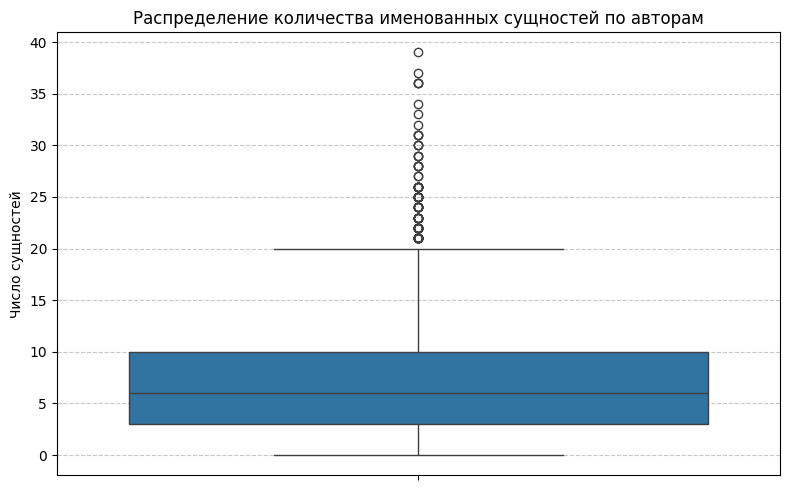

In [5]:
# Ячейка 3: диаграмма размаха (box plot)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_profiles, y="entity_count")
plt.title("Распределение количества именованных сущностей по авторам")
plt.ylabel("Число сущностей")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Всего уникальных сущностей: 18819
Топ-10 самых частых:
  USA: 2308
  National Science Foundation: 787
  National Institutes of Health: 532
  USA.: 228
  M: 209
  Massachusetts Institute of Technology: 201
  C: 174
  S: 162
  P: 154
  Department of Energy: 154


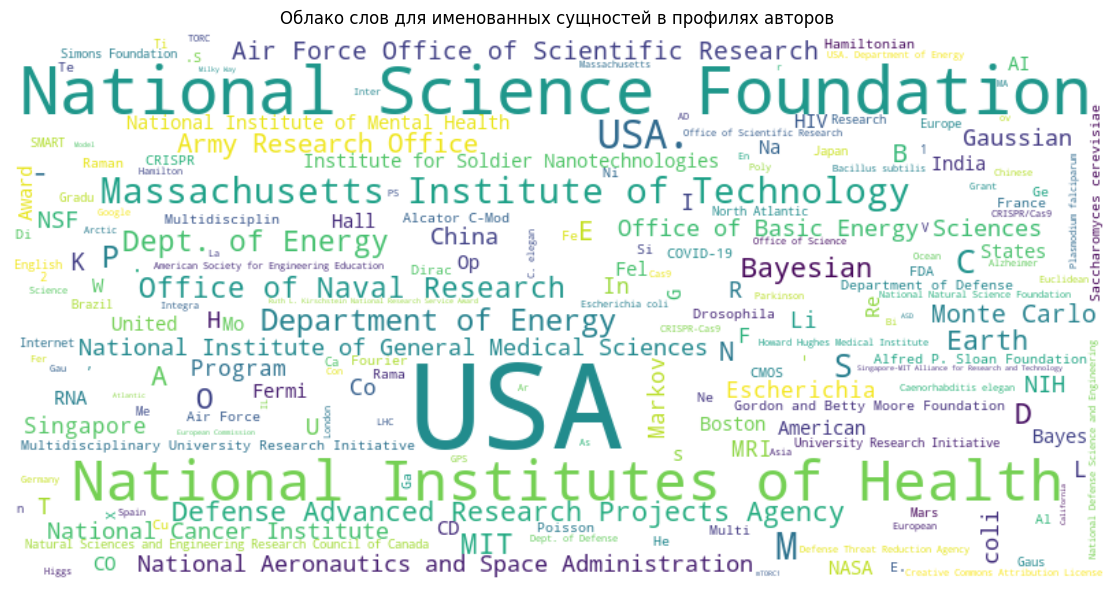

In [6]:
# Ячейка 4: облако слов для самых частотных сущностей
# Собираем все сущности в один список
all_entities = []
for ents in df_profiles["entities"].dropna():
    if ents.strip():
        all_entities.extend(ents.split("; "))

# Подсчитываем частоты
entity_freq = Counter(all_entities)
print(f"Всего уникальных сущностей: {len(entity_freq)}")
print("Топ-10 самых частых:")
for ent, freq in entity_freq.most_common(10):
    print(f"  {ent}: {freq}")

# Генерируем облако слов
wordcloud = WordCloud(width=800, height=400,
                      background_color="white",
                      max_words=200,
                      colormap="viridis").generate_from_frequencies(entity_freq)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Облако слов для именованных сущностей в профилях авторов")
plt.tight_layout()
plt.show()

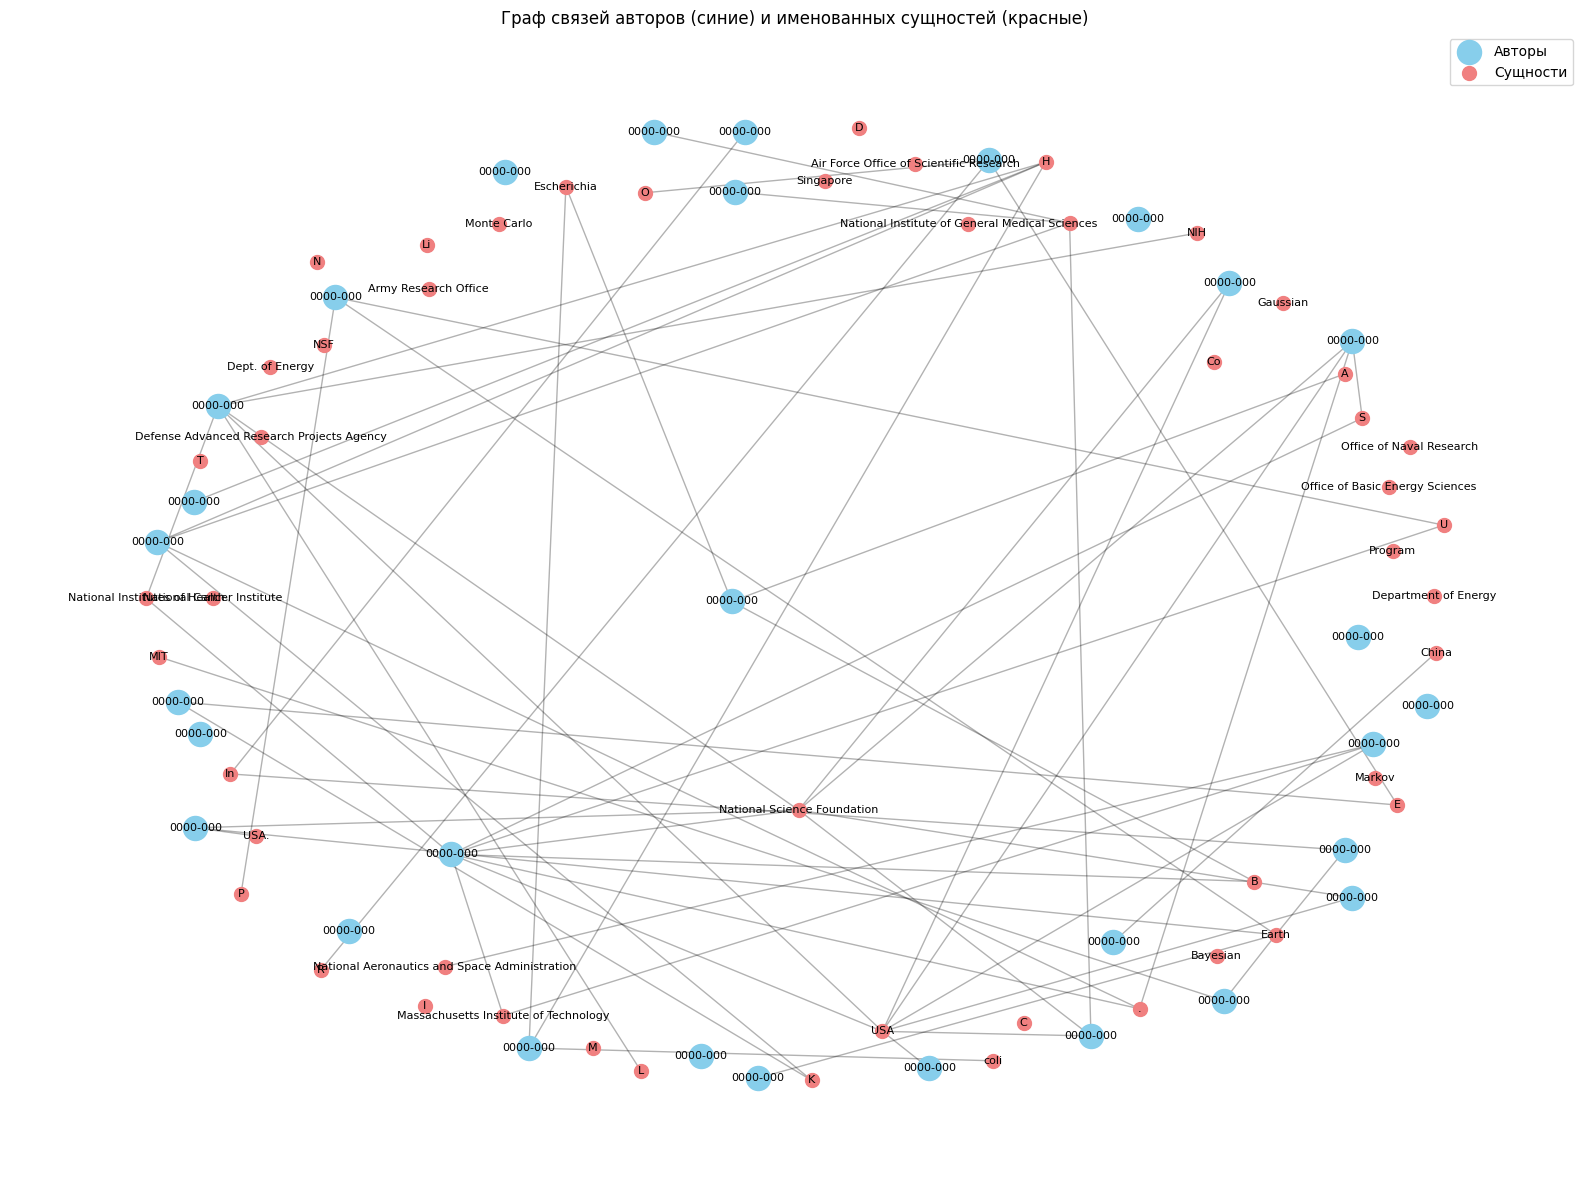

In [7]:
# Ячейка 5: построение графа "авторы – сущности"
# Ограничим граф для наглядности: возьмём топ-30 авторов по числу сущностей и топ-50 сущностей по частоте
top_authors = df_profiles.nlargest(30, "entity_count")[["orcid", "entities", "entity_count"]]
top_entities = [e for e, _ in entity_freq.most_common(50)]

# Создаём граф
G = nx.Graph()

# Добавляем узлы авторов (с атрибутом числа сущностей)
for _, row in top_authors.iterrows():
    author = row["orcid"]
    G.add_node(author, type="author", count=row["entity_count"])

# Добавляем узлы сущностей
for ent in top_entities:
    G.add_node(ent, type="entity")

# Добавляем рёбра (автор использует сущность)
for _, row in top_authors.iterrows():
    author = row["orcid"]
    if pd.notna(row["entities"]) and row["entities"].strip():
        for ent in row["entities"].split("; "):
            if ent in top_entities:
                G.add_edge(author, ent)

# Визуализация графа
plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, k=2, iterations=50)

# Цвет узлов: авторы – синие, сущности – красные
author_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "author"]
entity_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "entity"]

nx.draw_networkx_nodes(G, pos, nodelist=author_nodes, node_color="skyblue", node_size=300, label="Авторы")
nx.draw_networkx_nodes(G, pos, nodelist=entity_nodes, node_color="lightcoral", node_size=100, label="Сущности")

# Рёбра
nx.draw_networkx_edges(G, pos, alpha=0.3)

# Подписи только для авторов (или можно для сущностей, но их много)
labels = {n: n.split('/')[-1][:8] if n.startswith("http") else n for n in G.nodes()}  # сокращаем ORCID
nx.draw_networkx_labels(G, pos, labels, font_size=8)

plt.title("Граф связей авторов (синие) и именованных сущностей (красные)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

Всего узлов в графе: 24589
Всего рёбер: 38259


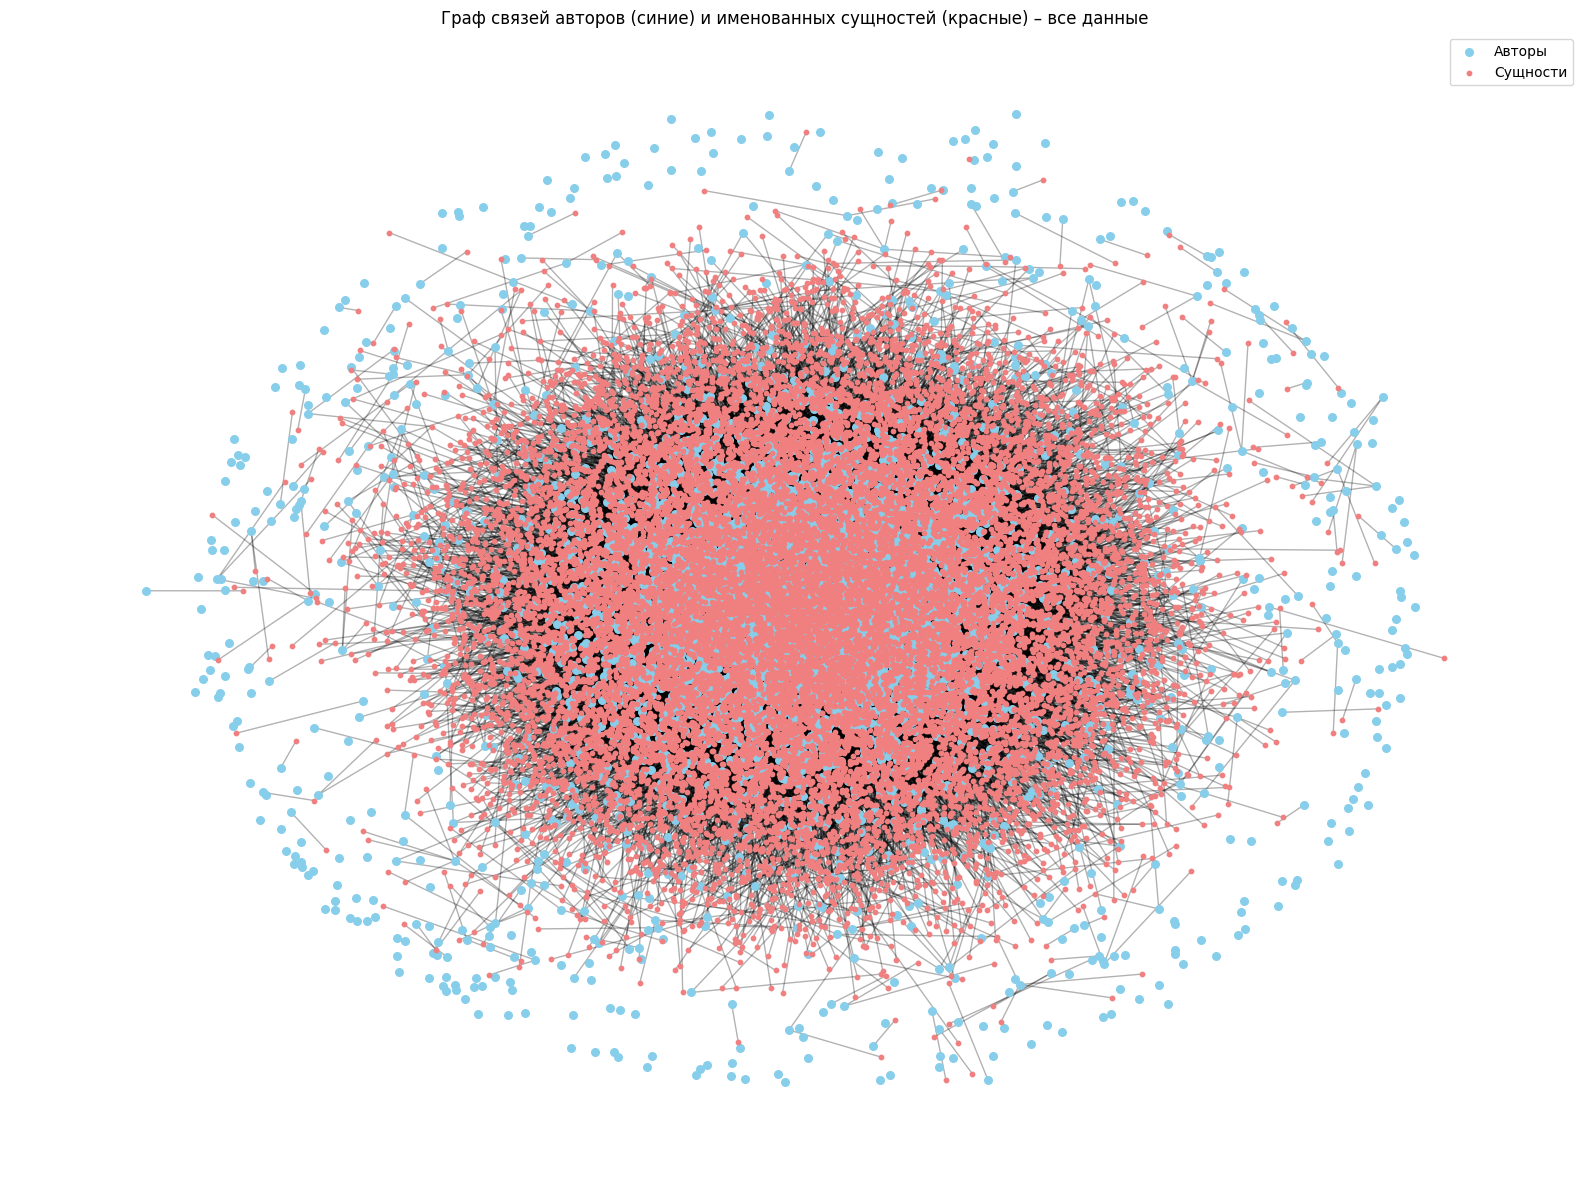

In [ ]:
# Ячейка 5: построение графа "авторы – сущности" (без ограничений, без подписей)
# Создаём граф
G = nx.Graph()

# Добавляем узлы авторов и рёбра с сущностями
for _, row in df_profiles.iterrows():
    author = row["orcid"]
    # Добавляем узел автора (с атрибутом)
    G.add_node(author, type="author", count=row.get("entity_count", 0))
    
    # Обрабатываем сущности
    if pd.notna(row["entities"]) and row["entities"].strip():
        for ent in row["entities"].split("; "):
            # Добавляем узел сущности (если ещё не существует)
            G.add_node(ent, type="entity")
            # Добавляем ребро
            G.add_edge(author, ent)

print(f"Всего узлов в графе: {G.number_of_nodes()}")
print(f"Всего рёбер: {G.number_of_edges()}")

# Визуализация графа
plt.figure(figsize=(16, 12))
pos = nx.spring_layout(G, k=2, iterations=50)

# Цвет узлов: авторы – синие, сущности – красные
author_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "author"]
entity_nodes = [n for n, attr in G.nodes(data=True) if attr.get("type") == "entity"]

nx.draw_networkx_nodes(G, pos, nodelist=author_nodes, node_color="skyblue", node_size=30, label="Авторы")
nx.draw_networkx_nodes(G, pos, nodelist=entity_nodes, node_color="lightcoral", node_size=10, label="Сущности")

# Рёбра
nx.draw_networkx_edges(G, pos, alpha=0.3)

# Подписи полностью удалены

plt.title("Граф связей авторов (синие) и именованных сущностей (красные) – все данные")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import json
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.graph_objs as go
import plotly.offline as pyo

# Предполагаем, что df_profiles уже содержит колонку "entities" после нормализации

# --- 1. Разбираем JSON строки в список словарей ---
def parse_entities(entities_str):
    if pd.isna(entities_str) or entities_str.strip() == "":
        return []
    try:
        return json.loads(entities_str)
    except Exception:
        return []

df_profiles['entities_parsed'] = df_profiles['entities'].apply(parse_entities)

# --- 2. Собираем статистику по типам сущностей ---
all_entities = [e for sublist in df_profiles['entities_parsed'] for e in sublist]

df_all_entities = pd.DataFrame(all_entities)
if not df_all_entities.empty:
    # Гистограмма распределения типов
    plt.figure(figsize=(10,6))
    sns.countplot(data=df_all_entities, x='type', order=df_all_entities['type'].value_counts().index)
    plt.title("Распределение типов именованных сущностей")
    plt.ylabel("Количество")
    plt.xlabel("Тип сущности")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Общая статистика
    total_entities = len(df_all_entities)
    print(f"Общее число сущностей: {total_entities}")

    entities_per_author = df_profiles['entities_parsed'].apply(len)
    print(f"Среднее число сущностей на автора: {entities_per_author.mean():.2f}")

    # Диаграмма размаха
    plt.figure(figsize=(8,6))
    sns.boxplot(x=entities_per_author)
    plt.title("Диаграмма размаха числа сущностей на автора")
    plt.xlabel("Количество сущностей")
    plt.tight_layout()
    plt.show()

    # --- 3. Облако слов ---
    all_words = [e['word'] for e in all_entities if isinstance(e['word'], str)]
    text_for_wc = ' '.join(all_words)
    wc = WordCloud(width=1200, height=600, background_color='white').generate(text_for_wc)
    plt.figure(figsize=(15,7))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title("Облако слов всех сущностей")
    plt.show()

    # --- 4. Интерактивный граф с 100 самыми популярными сущностями ---
    top_entities = [word for word, count in Counter(all_words).most_common(100)]
    
    # Создаём связи: entity -> список авторов
    edges = []
    for _, row in df_profiles.iterrows():
        author = row['orcid']
        for e in row['entities_parsed']:
            word = e['word']
            if word in top_entities:
                edges.append({'author': author, 'entity': word, 'type': e['type']})

    edges_df = pd.DataFrame(edges)
    
    # Nodes: авторы + сущности
    nodes = list(edges_df['author'].unique()) + top_entities
    node_indices = {n:i for i,n in enumerate(nodes)}

    # Edges
    edge_x = []
    edge_y = []
    for _, row in edges_df.iterrows():
        x0, x1 = node_indices[row['author']], node_indices[row['entity']]
        edge_x += [x0, x1, None]
        edge_y += [0,1,None]  # условно, для визуализации вертикального расположения

    # Scatter для вершин
    node_x = list(range(len(nodes)))
    node_y = [0]*len(df_profiles['orcid'].unique()) + [1]*len(top_entities)
    node_text = nodes

    fig = go.Figure()

    # Edges
    fig.add_trace(go.Scatter(
        x=edge_x, y=edge_y,
        line=dict(width=1, color='gray'),
        hoverinfo='none',
        mode='lines'
    ))

    # Nodes
    fig.add_trace(go.Scatter(
        x=node_x, y=node_y,
        mode='markers+text',
        marker=dict(size=10, color=['skyblue' if n in df_profiles['orcid'].values else 'orange' for n in nodes]),
        text=node_text,
        hovertext=node_text,
        hoverinfo='text',
        textposition="top center"
    ))

    fig.update_layout(
        title="Связь авторов и 100 самых популярных сущностей",
        showlegend=False,
        xaxis=dict(showticklabels=False),
        yaxis=dict(showticklabels=False),
        height=800,
        width=1200
    )

    # Сохраняем интерактивный граф в HTML
    pyo.plot(fig, filename="authors_entities_graph.html")
    print("Интерактивный граф сохранён в authors_entities_graph.html")
else:
    print("Нет сущностей для построения графиков")

In [12]:
import pandas as pd

INPUT_FILE = "orcid_profiles_with_ner.csv"
OUTPUT_FILE = "neo4j_ready.csv"

# загружаем
df = pd.read_csv(INPUT_FILE)

def clean_entities(entity_str):
    if pd.isna(entity_str):
        return ""

    entities = entity_str.split(";")

    cleaned = []
    for e in entities:
        e = e.strip()

        # фильтры мусора
        if len(e) < 3:
            continue
        if e.lower() in {"non", "ov", "etc"}:
            continue
        if e.isnumeric():
            continue

        cleaned.append(e)

    # убираем дубликаты
    cleaned = list(set(cleaned))

    return ";".join(cleaned)

# чистим entities
df["entities"] = df["entities"].apply(clean_entities)

# оставляем только нужное
df_final = df[["orcid", "title", "entities"]]

# удаляем пустые строки (без title)
df_final = df_final[df_final["title"].notna()]

# сохраняем
df_final.to_csv(OUTPUT_FILE, index=False, encoding="utf-8")

print("Готово:", OUTPUT_FILE)

Готово: neo4j_ready.csv


In [6]:
import socket
import time

ip = "185.242.245.96"
port = 443
interval = 1  # секунд между пакетами
max_packets = 40  # количество пакетов

try:
    # Устанавливаем соединение один раз
    s = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    s.settimeout(3)
    s.connect((ip, port))
    print("Соединение установлено успешно.")

    for i in range(max_packets):
        try:
            # Отправляем пустой пакет (можно заменить на реальные данные)
            s.sendall(b"")  # или s.sendall(b"ваши_данные")
            print(f"Пакет {i+1}: Отправлен успешно")
        except Exception as e:
            print(f"Пакет {i+1}: Ошибка при отправке — {e}")
            break  # или continue, если нужно продолжить после ошибки
        time.sleep(interval)

except Exception as e:
    print(f"Ошибка при подключении: {e}")
finally:
    s.close()
    print("Соединение закрыто.")

Соединение установлено успешно.
Пакет 1: Отправлен успешно
Пакет 2: Отправлен успешно
Пакет 3: Отправлен успешно
Пакет 4: Отправлен успешно
Пакет 5: Отправлен успешно
Пакет 6: Отправлен успешно
Пакет 7: Отправлен успешно
Пакет 8: Отправлен успешно
Пакет 9: Отправлен успешно
Пакет 10: Отправлен успешно
Пакет 11: Отправлен успешно
Пакет 12: Отправлен успешно
Пакет 13: Отправлен успешно
Пакет 14: Отправлен успешно
Пакет 15: Отправлен успешно
Пакет 16: Отправлен успешно
Пакет 17: Отправлен успешно
Пакет 18: Отправлен успешно
Пакет 19: Отправлен успешно
Пакет 20: Отправлен успешно
Пакет 21: Отправлен успешно
Пакет 22: Отправлен успешно
Пакет 23: Отправлен успешно
Пакет 24: Отправлен успешно
Пакет 25: Отправлен успешно
Пакет 26: Отправлен успешно
Пакет 27: Отправлен успешно
Пакет 28: Отправлен успешно
Пакет 29: Отправлен успешно
Пакет 30: Отправлен успешно
Пакет 31: Отправлен успешно
Пакет 32: Отправлен успешно
Пакет 33: Отправлен успешно
Пакет 34: Отправлен успешно
Пакет 35: Отправлен успеш